# Kex

> Transfer of a CNN for exchangeable potassium (Kex) from OSSL to Fukushima: zero-shot, head-only, fine-tuned and Fukushima-only models

In [ ]:
import numpy as np, pandas as pd
from fastcore.test import *
from soilspecdata.all import load_ossl
from ossl_fuku_transfer.data import *
from ossl_fuku_transfer.transfer import *

/Users/franckalbinet/pro/dev/soilspec/ossl-fuku-transfer/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Every code cell reads OSSL or the Fukushima data, and is marked `#| fukudata`. The outputs come from a local run on an Apple silicon GPU (MPS). `02_transfer` defines the functions used here.

## Data

OSSL MIR spectra on the shared grid, with Kex in cmolc/kg. The models predict `log1p(Kex)`:

In [ ]:
#| fukudata
om = load_ossl().mir(wmin=shared_wns[0], wmax=shared_wns[-1])
Xo, yo, _ = om.xy('k.ext_usda.a725_cmolc.kg')
yo = np.log1p(yo.ravel())
Xo.shape

(57674, 1675)

The Fukushima spectra, with Kex converted from mg K₂O per 100 g to cmolc/kg. The test set is the Cs137 study's test set:

In [ ]:
#| fukudata
fuku = load_fuku()
fuku.source = fuku.source.assign(target=fuku.source['soil_ex_K2O'] / mg_k2o_per_cmolc)
Xf, yf, idf = fuku.xy('target')
yf = np.log1p(yf.ravel())
_, test_ids = cs137_split()
is_test = np.isin(idf, test_ids)
yt = yf[is_test]
Xf.shape, int(is_test.sum())

((1388, 1675), 341)

## Pretraining

Each preprocessing is fitted on OSSL and applied to Fukushima. `pretrain` trains on OSSL, or loads the weights of an earlier run. The table shows the last epoch of each pretraining, with the R² of the OSSL validation set:

In [ ]:
#| fukudata
X = {k: (p.fit_transform(Xo), p.transform(Xf)) for k, p in preprocessings().items()}
pretrained = {k: pretrain(Xo_k, yo, f'ossl_kex_{k}') for k, (Xo_k, _) in X.items()}
pd.DataFrame({k: pretrain_history(f'ossl_kex_{k}').iloc[-1] for k in X}).T.round(3)

,train_loss,valid_loss,r2_score
snv,0.032,0.037,0.744
snv_d1,0.023,0.030,0.794


## Comparison

Each Fukushima model trains with five seeds. The table gives the mean and standard deviation over the seeds of R² and correlation `r` of `log1p(Kex)`, and of the RMSE and bias of Kex in cmolc/kg, on the test samples:

In [ ]:
#| fukudata
res, preds = compare(pretrained, {k: Xf_k for k, (_, Xf_k) in X.items()}, yf, is_test)
summarise(res).round(3)

R²             r  ...          bias       
                               mean    std   mean  ...    std   mean    std
preprocessing model                                ...                     
snv           zero-shot      -0.647  0.000  0.013  ...  0.000 -0.100  0.000
              head only       0.109  0.004  0.335  ...  0.001 -0.041  0.008
              fine-tuned      0.078  0.003  0.285  ...  0.001 -0.044  0.006
              Fukushima only  0.156  0.020  0.422  ...  0.004 -0.037  0.009
snv_d1        zero-shot      -0.820  0.000  0.126  ...  0.000  0.285  0.000
              head only       0.108  0.006  0.334  ...  0.002 -0.059  0.008
              fine-tuned      0.088  0.004  0.314  ...  0.001 -0.058  0.007
              Fukushima only  0.300  0.015  0.553  ...  0.004 -0.042  0.014

[8 rows x 8 columns]

For scale, the standard deviation of the test Kex values, in cmolc/kg:

In [ ]:
#| fukudata
round(float(np.expm1(yt).std()), 3)

0.406

Predictions of the first seed against the observed values:

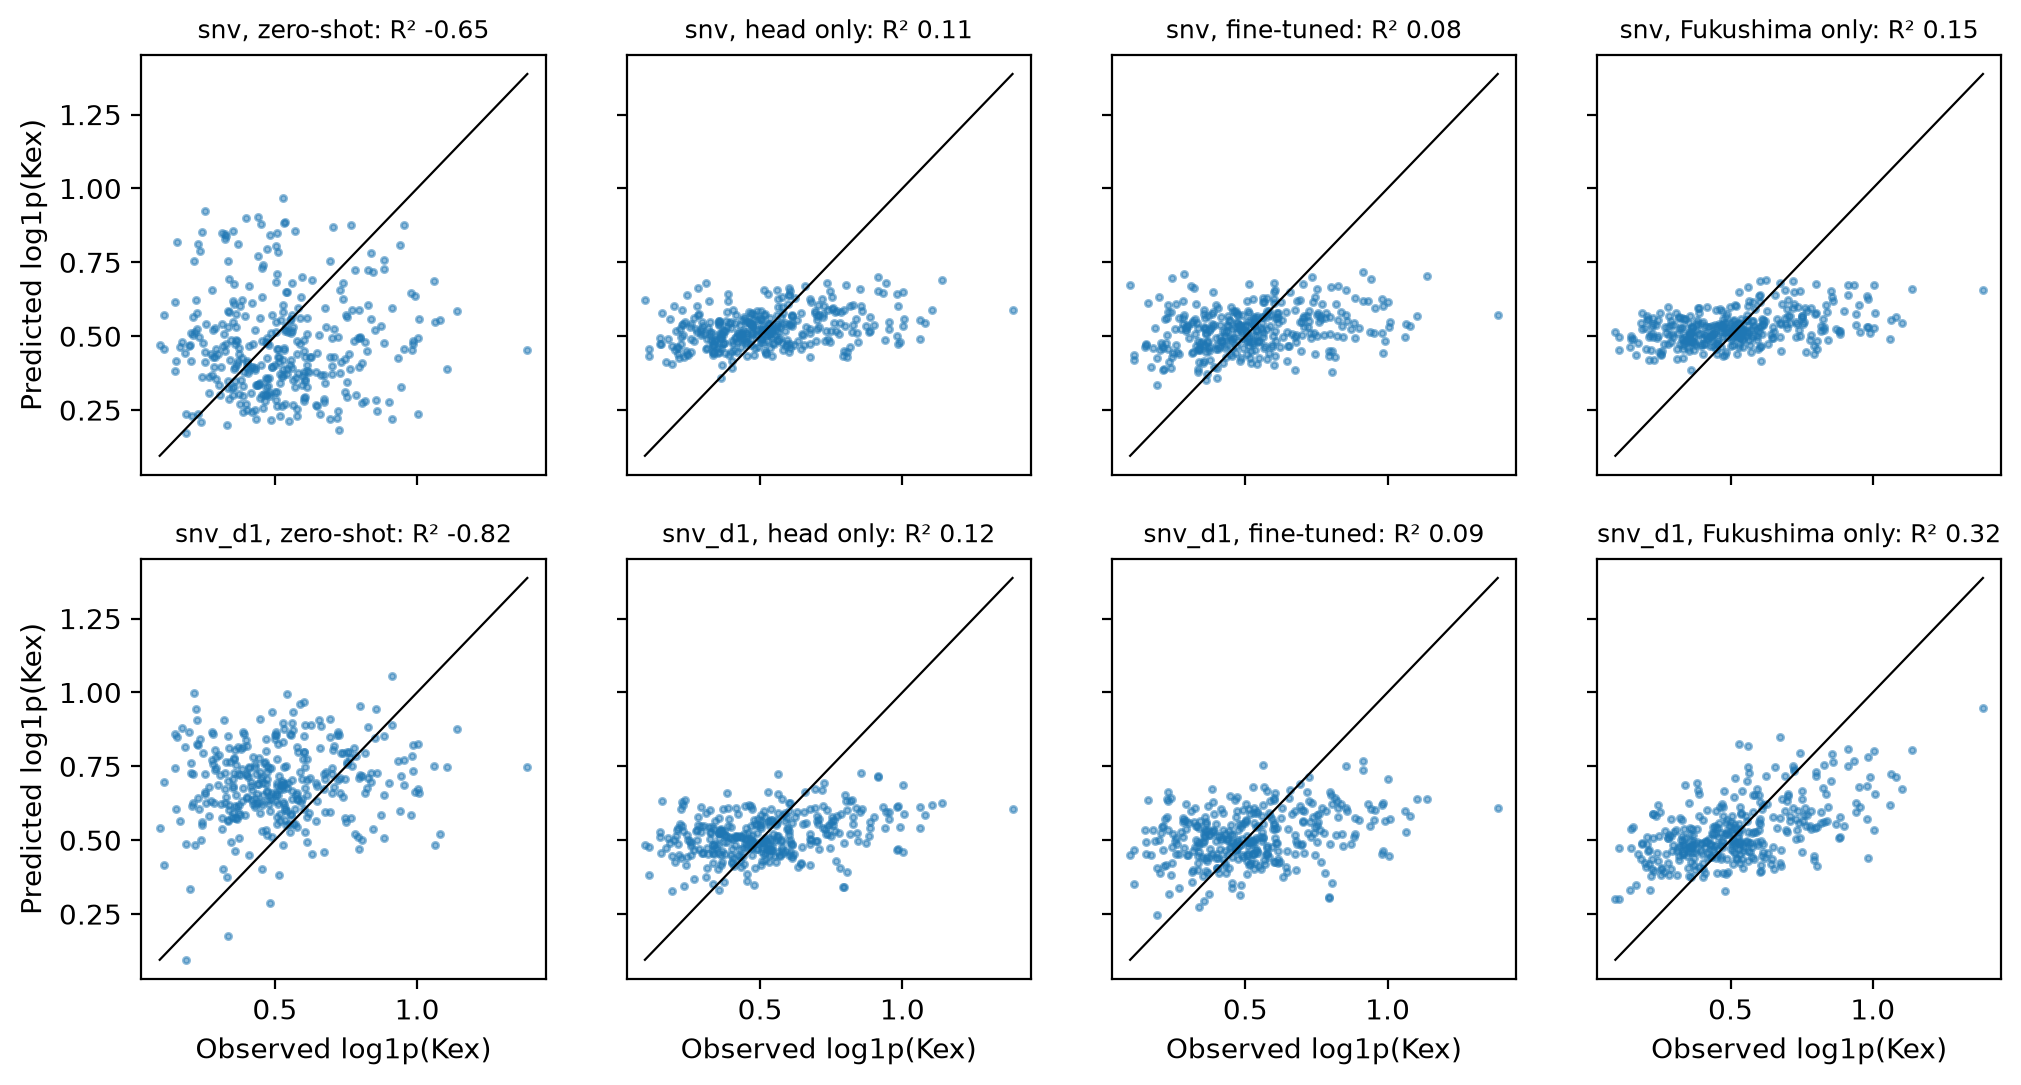

In [ ]:
#| fukudata
plot_preds(preds, yt, label='log1p(Kex)');

## Checks

The OSSL validation R² covers OSSL's whole Kex range. The pretrained models are scored again on their OSSL validation samples, first all of them, then those within the 5th to 95th percentile of Fukushima Kex:

In [ ]:
#| fukudata
lo, hi = np.quantile(yf, [0.05, 0.95])
np.expm1([lo, hi]).round(2), pd.DataFrame({k: range_check(Xo_k, yo, pretrained[k], lo, hi) for k, (Xo_k, _) in X.items()}).T.round(3)

(array([0.22, 1.63]),
          n all  R² all  r all  n in range  R² in range  r in range
 snv     5767.0   0.744  0.863      3227.0        0.259       0.670
 snv_d1  5767.0   0.794  0.892      3227.0        0.378       0.725)

A spectral model predicts Kex partly through the soil properties that Kex varies with. Spearman correlations of Kex with CEC and with total carbon, in OSSL, in OSSL samples within Fukushima's Kex range, in OSSL Andisols, and in Fukushima:

In [ ]:
#| fukudata
ocols = {'k.ext_usda.a725_cmolc.kg': 'Kex', 'cec_usda.a723_cmolc.kg': 'CEC', 'c.tot_usda.a622_w.pct': 'C'}
op_ = om.source[list(ocols)].rename(columns=ocols).reindex(om.sample_ids)
fp = fuku.source.loc[fuku.sample_ids, ['target', 'soil_CEC', 'soil_C']].set_axis(['Kex', 'CEC', 'C'], axis=1)
in_rng = op_.Kex.between(*np.expm1([lo, hi]))
andisol = om.source['pedon.taxa_usda_txt'].reindex(om.sample_ids).astype('string').str.contains(r'[a-z]ands?\b|andepts?\b', na=False).to_numpy()
def corrs(df): return {'Kex–CEC': df.Kex.corr(df.CEC, method='spearman'), 'Kex–C': df.Kex.corr(df.C, method='spearman'), 'CEC–C': df.CEC.corr(df.C, method='spearman'), 'n': len(df.dropna())}
pd.DataFrame({'OSSL': corrs(op_), 'OSSL in Fukushima range': corrs(op_[in_rng]), 'OSSL Andisols': corrs(op_[andisol]), 'Fukushima': corrs(fp)}).T.round(2)

,Kex–CEC,Kex–C,CEC–C,n
OSSL,0.60,0.36,0.56,53360.0
OSSL in Fukushima range,0.33,0.18,0.39,30494.0
OSSL Andisols,0.47,0.36,0.67,1444.0
Fukushima,0.29,0.03,0.41,1385.0


## Error analysis

Mean absolute error of `log1p(Kex)` with the derivative preprocessing, by soil type, year and measurement batch. Each model's predictions are averaged over the seeds first:

In [ ]:
#| fukudata
props = fuku.source.loc[idf[is_test]]
error_table(preds, yt, props['Soil_type_describe'], 'snv_d1').round(3)

,head only,fine-tuned,Fukushima only,n
Andosols,0.174,0.173,0.174,44
Forest soil,0.171,0.170,0.160,27
Glay soil,0.189,0.197,0.105,6
Lowland soil,0.149,0.153,0.135,244
Peat soil,0.236,0.230,0.175,14
Red yellow soil,0.195,0.200,0.177,6


In [ ]:
#| fukudata
error_table(preds, yt, props['year'].astype(int), 'snv_d1').round(3)

,head only,fine-tuned,Fukushima only,n
2013,0.198,0.198,0.171,34
2014,0.179,0.176,0.167,53
2015,0.125,0.130,0.116,48
2016,0.135,0.136,0.117,58
2017,0.151,0.149,0.148,37
2018,0.174,0.182,0.151,46
2019,0.157,0.163,0.137,49
2020,0.187,0.195,0.174,16


In [ ]:
#| fukudata
error_table(preds, yt, sample_batches(idf[is_test]), 'snv_d1').round(3)

,head only,fine-tuned,Fukushima only,n
batch 1,0.170,0.171,0.157,110
batch 2,0.154,0.158,0.137,231


## Findings

The pretrained models come from one pretraining run each. The Fukushima-side training was repeated with five seeds, and the standard deviations over the seeds are small, at most 0.02 in R². Training on MPS is not fully deterministic, and the variation between pretraining runs is not measured.

Pretraining works. The OSSL validation R² of `log1p(Kex)` is 0.74 with SNV and 0.79 with the derivative. On OSSL validation samples within Fukushima's Kex range (0.22 to 1.63 cmolc/kg), the correlation stays at 0.67 and 0.73.

The OSSL models do not transfer to Fukushima without training. Their zero-shot R² is negative, and their correlation with the observed values is 0.01 with SNV and 0.13 with the derivative. The narrower range does not explain this. The relation between Kex and the soil does not explain it either: the Spearman correlation of Kex with CEC is 0.29 in Fukushima and 0.33 in OSSL samples within the same range.

The CNN trained on Fukushima samples only is the best model: R² 0.30 and correlation 0.55 with the derivative. Training a linear head on the frozen OSSL backbone gives R² 0.11. Fine-tuning gives 0.08 to 0.09. The fine-tuned backbone trains at a maximum learning rate of 5e-6 (see `02_transfer`), so it stays close to the OSSL weights. The comparison therefore tests the OSSL features, not full fine-tuning.

The errors vary little by soil type, year or measurement batch. The Fukushima-only model has the lowest error in almost every group.